In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yashbhattme/predictive-maintainance/ai4i2020.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
data = pd.read_csv("/kaggle/input/datasets/yashbhattme/predictive-maintainance/ai4i2020.csv")
df = pd.DataFrame(data)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.shape

(10000, 14)

In [5]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [9]:
df["Tool wear [min]"].value_counts()

Tool wear [min]
0      120
2       69
5       63
7       58
59      58
      ... 
237      1
239      1
241      1
251      1
253      1
Name: count, Length: 246, dtype: int64

In [10]:
# CONCLUSION The target variable Machine failure is highly imbalanced, with only 3.39% of observations representing machine failures. SHAPE IS 10K,14. NO NULL VALUES AND NO DUPLICATE VALUES ,  machinefailure is target columns . twf,hdf,pwf,osf,rnf should e oject

# EDA

In [11]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [12]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

# numerical univariate

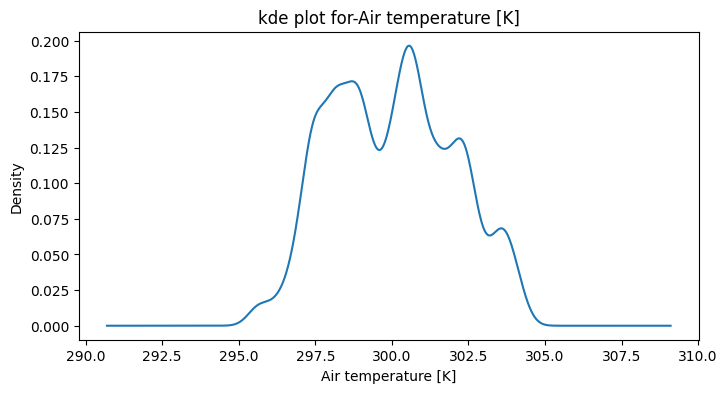

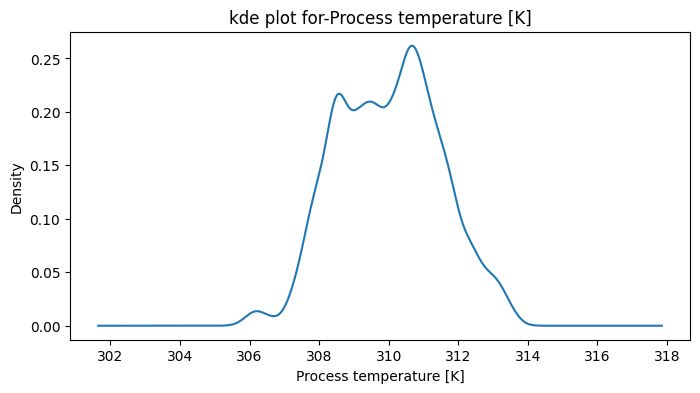

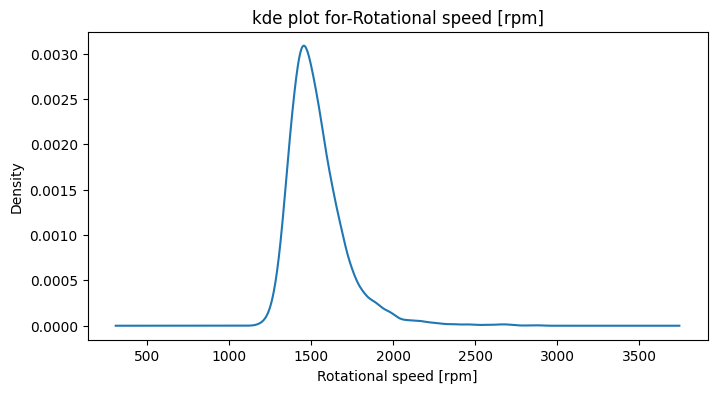

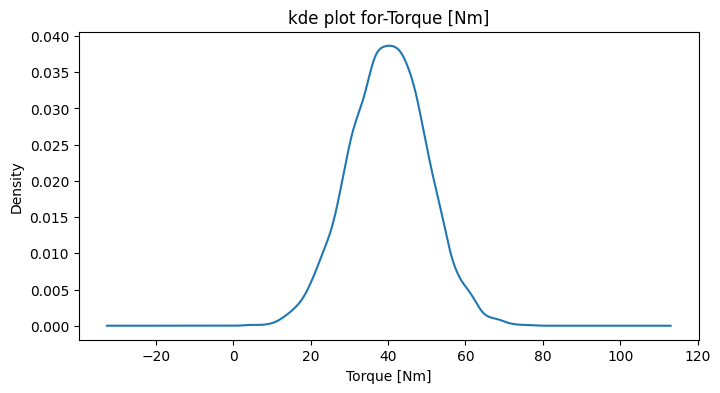

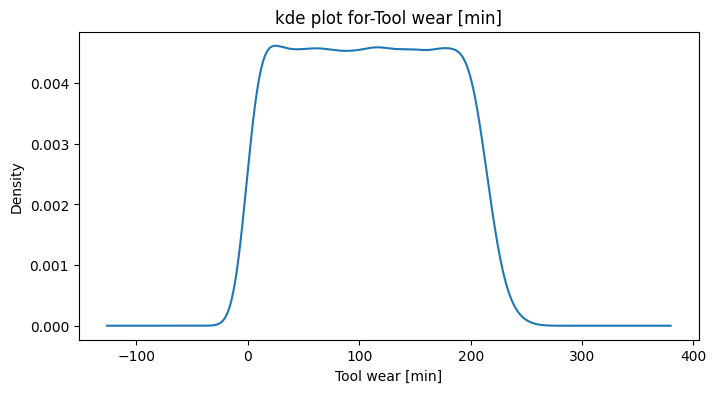

In [13]:
# univariate analysis - numerical
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="kde")
    plt.title(f"kde plot for-{col}")
    plt.xlabel(col)
    plt.show()

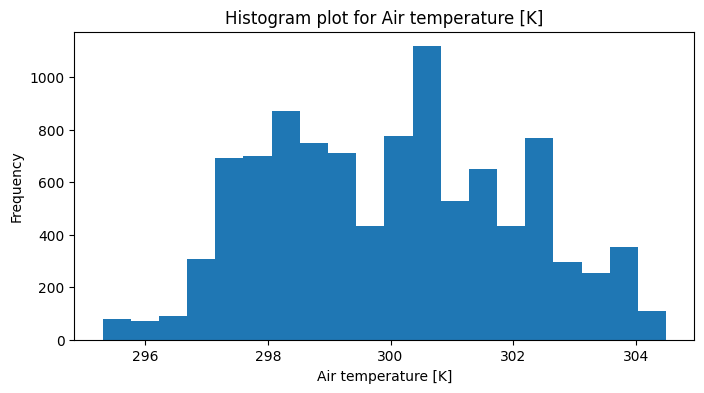

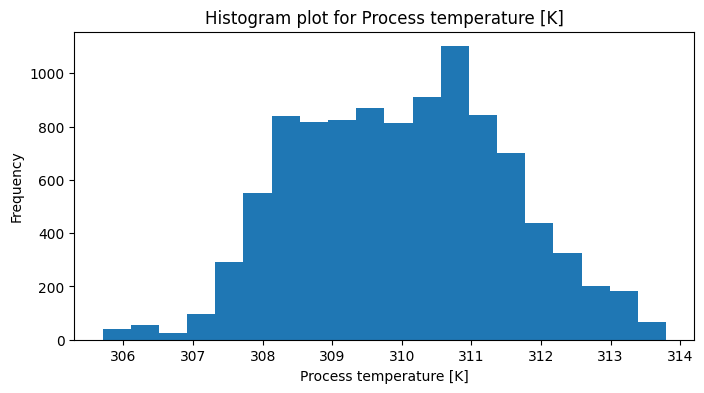

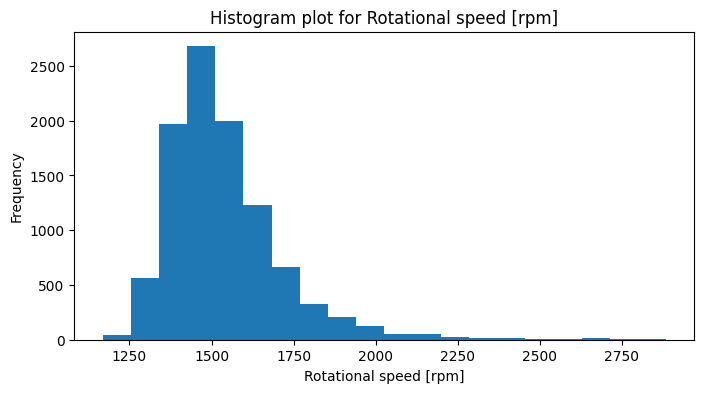

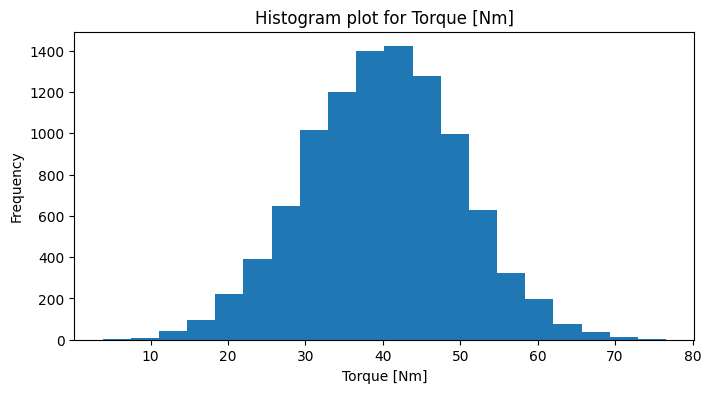

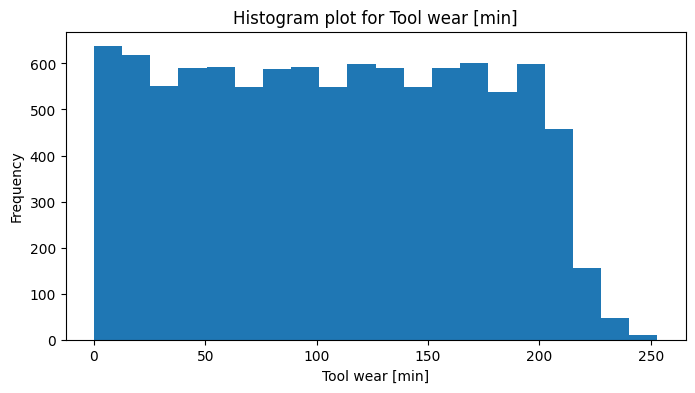

In [14]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="hist",bins=20)
    plt.xlabel(col)
    plt.title(f"Histogram plot for {col}")
    plt.show()
    

In [15]:
# tool wear right skewed very slight , 0 to 10 peak , data is not concentrated at one place thus spread is low. torque 40 to 43 peak normal distriution slight left skewed.rotation speed is highly right skewed.approx 1500rpm is peak.process temperature 310.6 to 311k peak high spread 4 peaks quadmodal left skewed. air temp high spread 4 peak quadmodal 300.2 to 300.4 longest peak left skewed

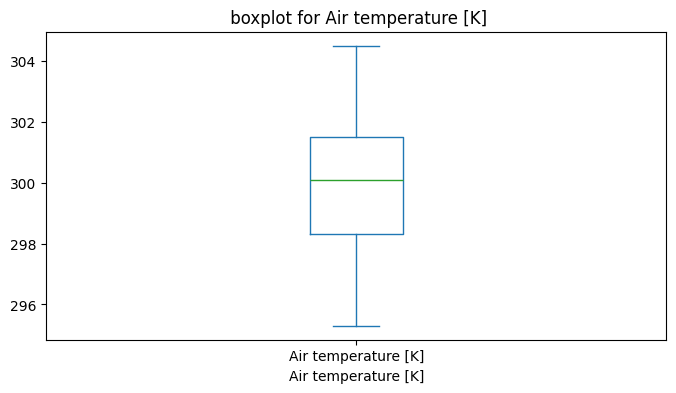

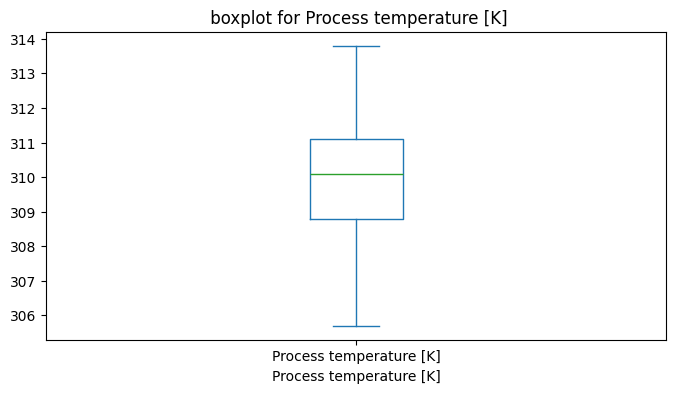

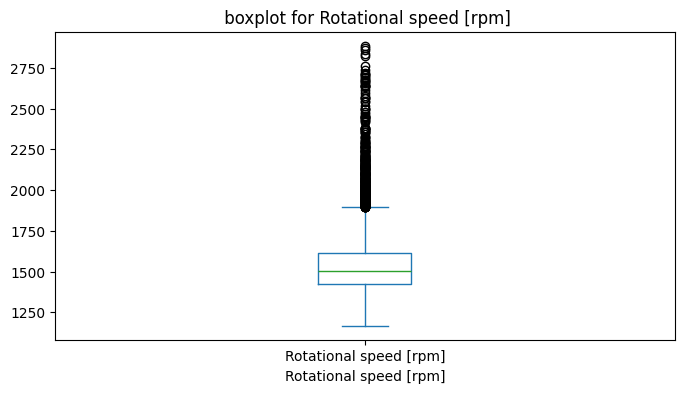

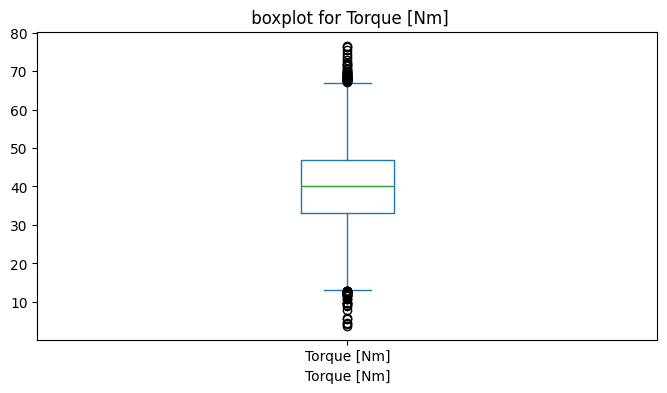

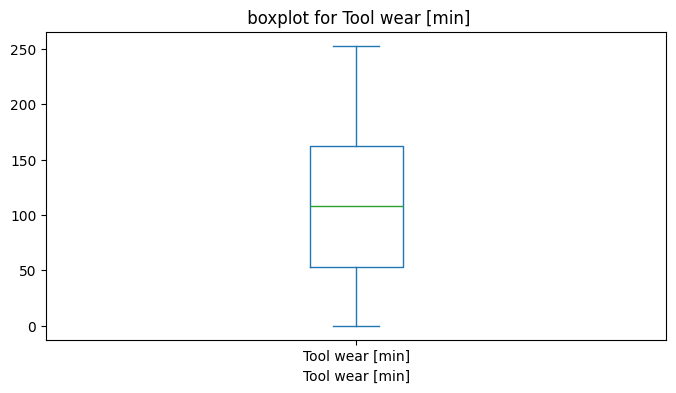

In [16]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].plot(kind="box")
    plt.xlabel(col)
    plt.title(f" boxplot for {col}")
    plt.show()
    

In [17]:
# zero outliers in tool wear , process temperature , air temperature , rpm has many outliers aove its max value tho it is not confirmed. torque also has outliers oth aove max value and min value ut needs to investigate further

In [18]:
df["HDF"].value_counts()

HDF
0    9885
1     115
Name: count, dtype: int64

In [19]:
# from sklearn.preprocessing import LabelEncoder
# cols = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
#        'RNF'] 
# le = LabelEncoder()
# df[cols] = le.fit_transform(cols)

In [20]:
cols = ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'] 
for col in cols:
    df[col] = df[col].astype(str)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  object 
 9   TWF                      10000 non-null  object 
 10  HDF                      10000 non-null  object 
 11  PWF                      10000 non-null  object 
 12  OSF                      10000 non-null  object 
 13  RNF                      10000 non-null  object 
dtypes: float64(3), int64(3)

# categorical univariate

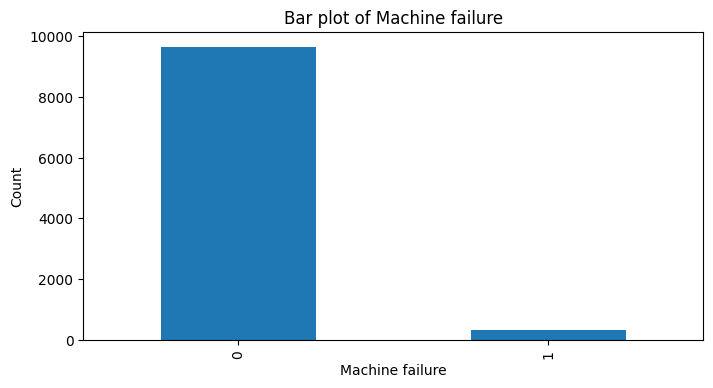

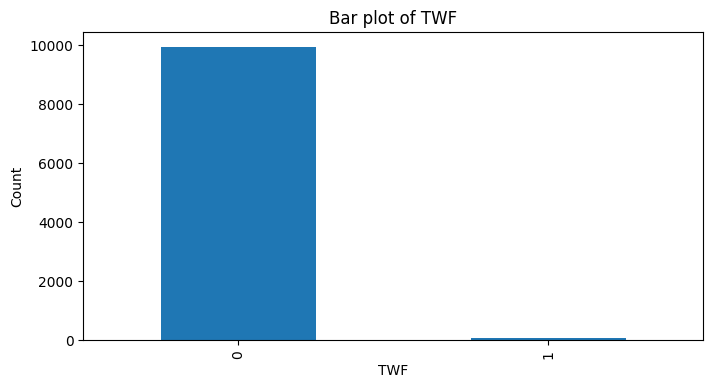

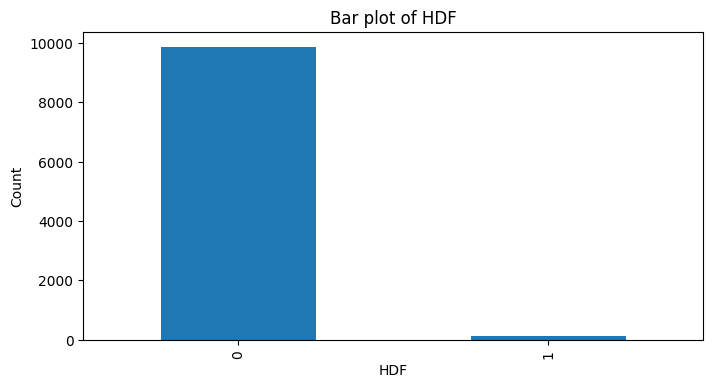

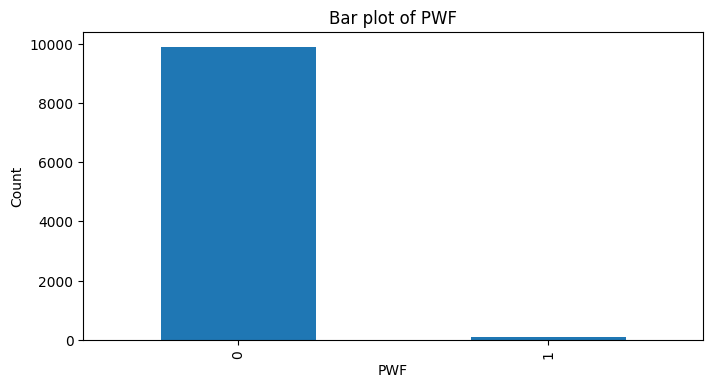

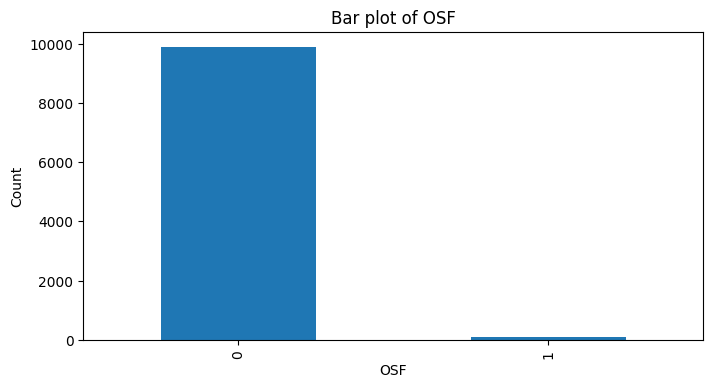

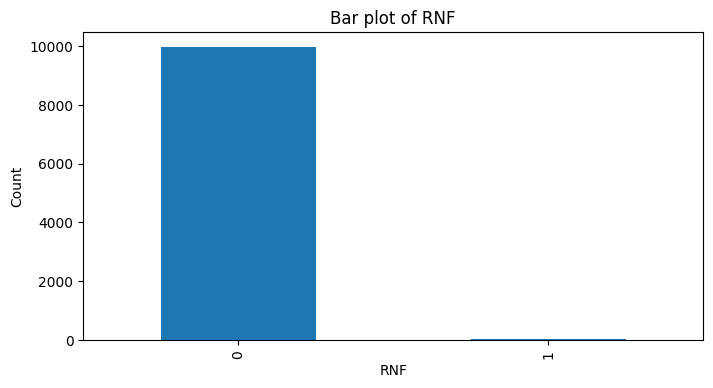

In [22]:
# univariate analysis - categorical columns
for col in cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"Bar plot of {col}")
    plt.show()



In [23]:
# overall bar of rnf,twf,osf,pwf,hdf,machine failure are highly imlanced columns with maximum counts at machine did not fail. and in type L is around 6000 ,  M id around 3000 and H is around 1000 

# conclusion-I

**Univariate Analysis Conclusion

The numerical features show different distributions. Tool wear is slightly right-skewed, while rotational speed is highly right-skewed. Torque is approximately normally distributed with slight left skewness. Air temperature and process temperature show multimodal distributions with relatively high spread. Potential outliers were observed mainly in rotational speed and torque, which require further investigation.

The categorical analysis shows that Type L is the most common category, followed by Type M and Type H. The binary failure-related variables are highly imbalanced, with the majority of observations having a value of 0 (no failure). The target variable Machine failure is also highly imbalanced, with only a small percentage of machines experiencing failure.**

# numerical bivariate

In [24]:
df.describe()
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

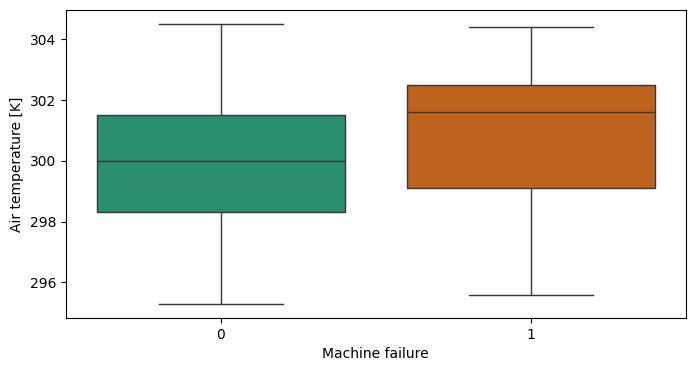

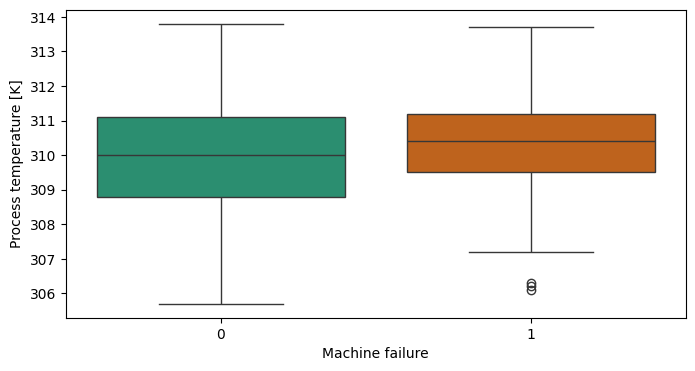

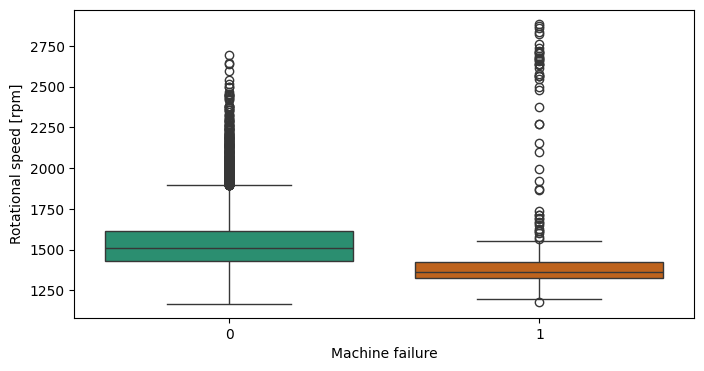

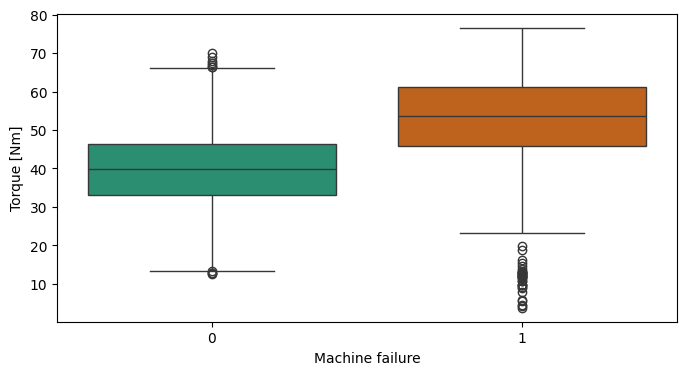

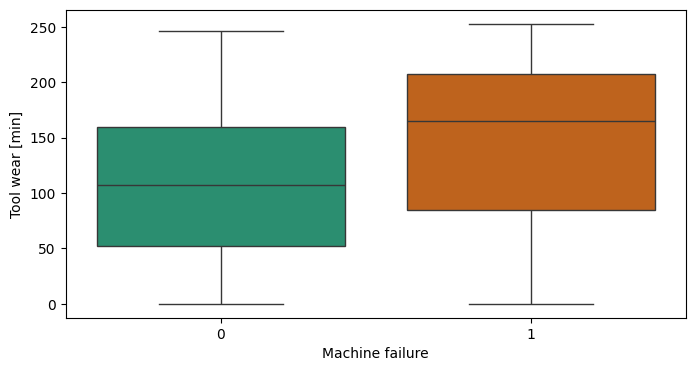

In [25]:
cols = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
for col in cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x="Machine failure" , y=col,data=df,palette = "Dark2")
    plt.show()

In [26]:
# total wear v machine failure , machine failure 0s and 1s median are very different where 1s has more median. inside the 1s box median is not at perfectly centered more aligned towards 75%, 1s IQR overall more than 0s. failures appeared to directly proportional to tool wear. torque v machine failure 0s and 1s median has much difference and 1s has higher median 1s also has more outliers at min side here while 0s has less outliers that 1s ut in oth max and min side. spread is nearly same and it appears that torque also directly prop to mach failure.machine v rotation speed here rotation is inverse prop to failure,1s spread is very low . oth 0s and 1s median are not same , median of 1s is low. oth 0s and 1s has outliers.

# **categorical bivariate**

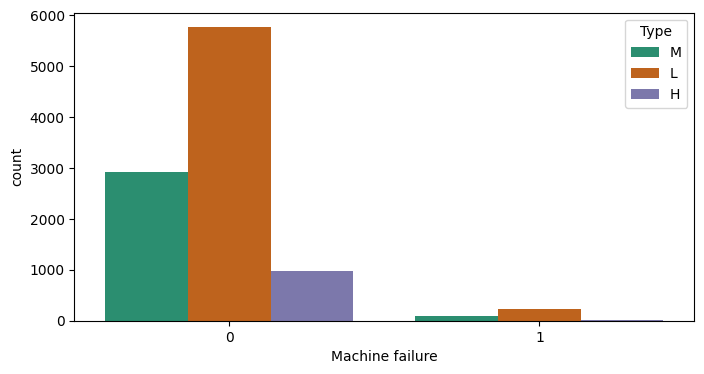

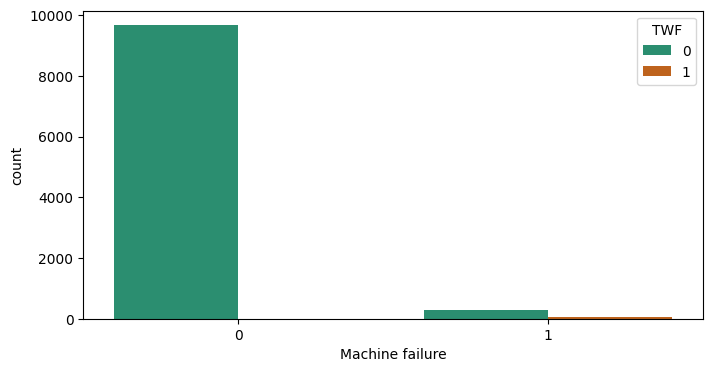

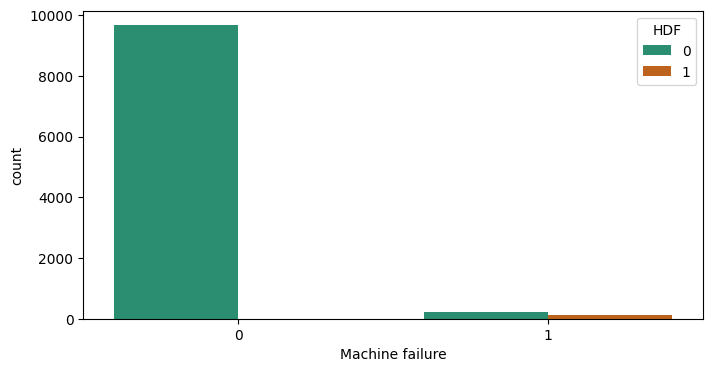

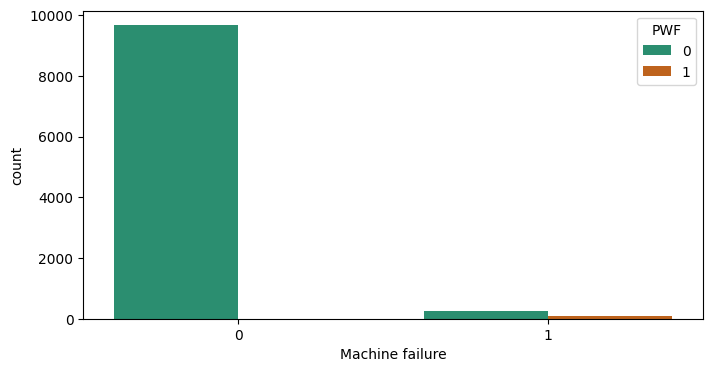

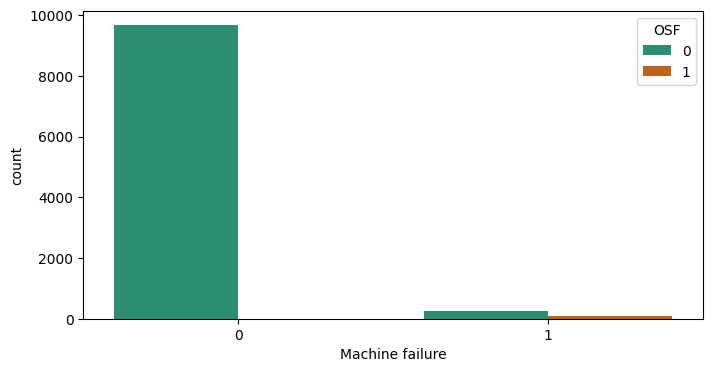

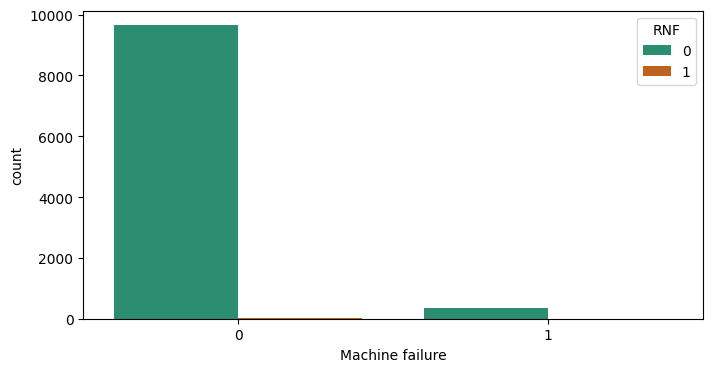

In [27]:
cols = ['Type', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF']
for col in cols:
    plt.figure(figsize=(8,4))
    sns.countplot(x='Machine failure', hue=col, data=df,palette="Dark2")
    plt.show()

In [28]:
# rnf no machine fail when no rnf occur majority class. osf no machine fail when no osf occur in majority. same for pwf , hdf, twf so in my pov if machine these categories problem dont occur then machine fail do not occur.and in type L has more no machine fail and L also has more machine fail but in respect to overall machine fail the machine fail count are very less

# Conclusion-II
Tool wear shows a noticeable difference between failed and non-failed machines, with failed machines having a higher median tool wear and greater variation.
Torque also shows a higher median for failed machines, suggesting an association between higher torque and machine failure.
Rotational speed has a lower median for failed machines, indicating that lower rotational speed may be associated with failure.
The failure-mode features (TWF, HDF, PWF, OSF, and RNF) show a strong association with Machine failure. When these indicators are 0, most observations belong to the non-failure class.
Type L has the highest absolute number of both failures and non-failures, but this is largely because L is the most common machine type. Failure rates by type would be more informative than raw counts.
Overall, several features show noticeable differences between failure and non-failure observations and may contain useful predictive information.
These relationships represent associations, not causal relationships, and should be investigated further during multivariate analysis and modeling.
The failure-mode indicators will require careful leakage analysis before being used as predictive features.

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  object 
 9   TWF                      10000 non-null  object 
 10  HDF                      10000 non-null  object 
 11  PWF                      10000 non-null  object 
 12  OSF                      10000 non-null  object 
 13  RNF                      10000 non-null  object 
dtypes: float64(3), int64(3)

# Multivariate analysis

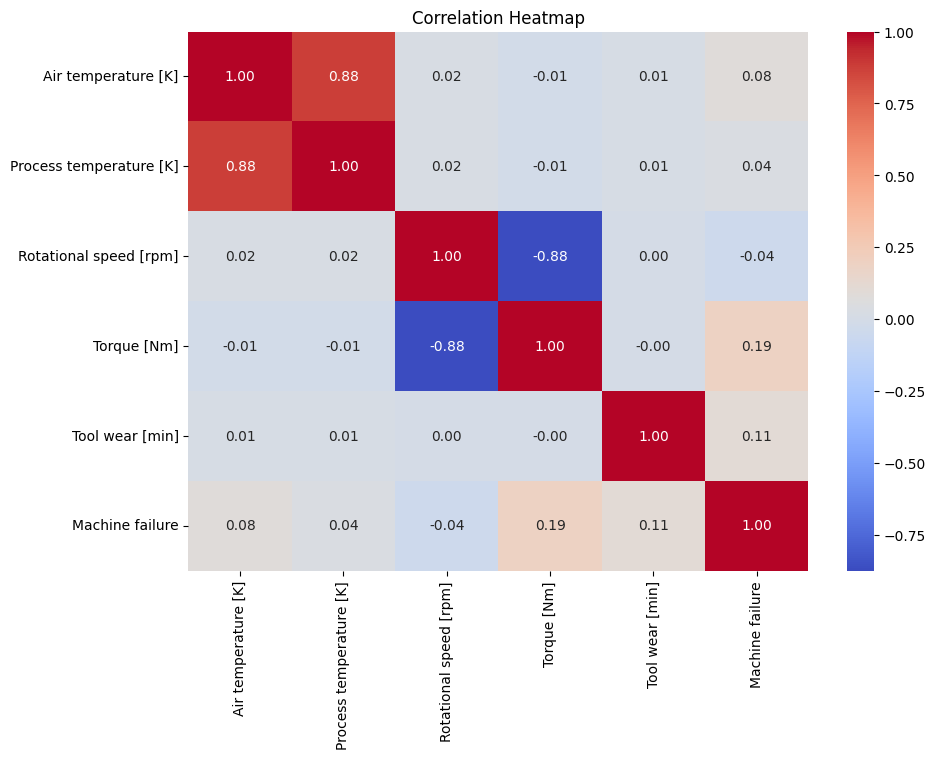

In [30]:
num_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure'
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

<Axes: xlabel='Rotational speed [rpm]', ylabel='Torque [Nm]'>

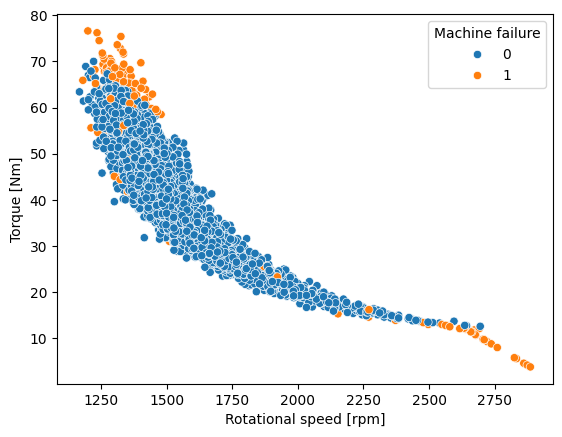

In [31]:
sns.scatterplot(
    data=df,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure'
)

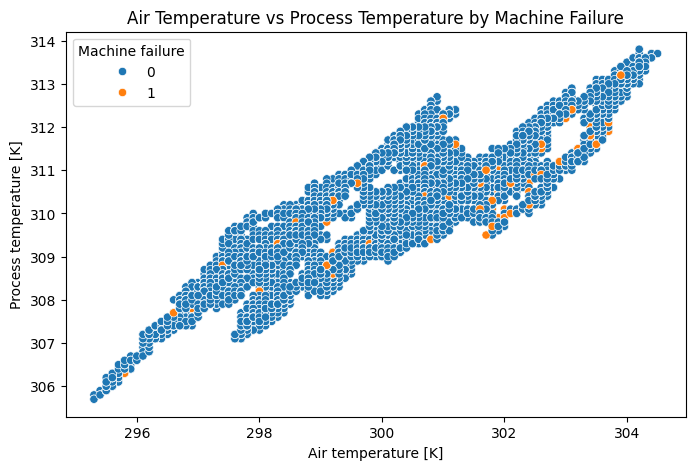

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Air temperature [K]',
    y='Process temperature [K]',
    hue='Machine failure'
)

plt.title('Air Temperature vs Process Temperature by Machine Failure')
plt.show()

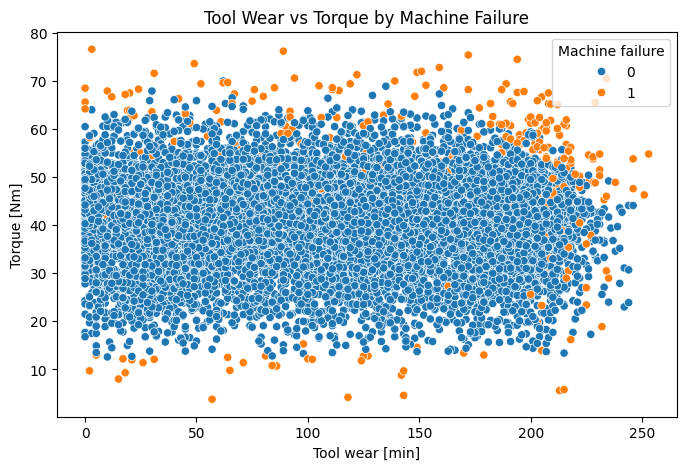

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Tool wear [min]',
    y='Torque [Nm]',
    hue='Machine failure'
)

plt.title('Tool Wear vs Torque by Machine Failure')
plt.show()

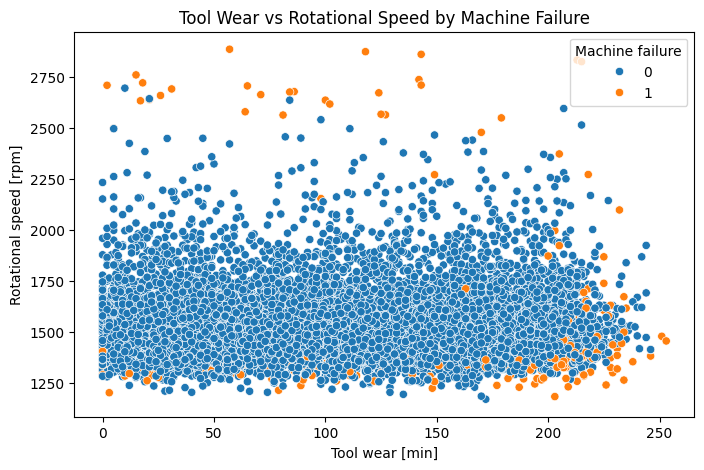

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Tool wear [min]',
    y='Rotational speed [rpm]',
    hue='Machine failure'
)

plt.title('Tool Wear vs Rotational Speed by Machine Failure')
plt.show()

# Conclusion-III
Air temperature and process temperature show a strong positive relationship, with a correlation of approximately 0.88.
Rotational speed and torque show a strong negative and nonlinear relationship, with a correlation of approximately -0.88.
Machine failure observations appear more frequently in regions of lower rotational speed and higher torque.
The combination of tool wear and torque shows some association with machine failure, particularly at higher torque values, but there is substantial overlap between failed and non-failed machines.
The combination of tool wear and rotational speed shows some concentration of failures at lower rotational speeds, but again there is considerable overlap.
No combination of the investigated numerical features provides a clear separation between failed and non-failed machines.
The strong correlations between some predictor variables indicate potential multicollinearity, which should be considered during later modeling.
Overall, machine failure appears to involve multiple variables and potentially nonlinear relationships, suggesting that simple linear relationships alone may not be sufficient for prediction.

# Basic Cleaning

In [35]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  object 
 9   TWF                      10000 non-null  object 
 10  HDF                      10000 non-null  object 
 11  PWF                      10000 non-null  object 
 12  OSF                      10000 non-null  object 
 13  RNF                      10000 non-null  object 
dtypes: float64(3), int64(3)

In [38]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [39]:
df.drop(columns=["UDI","Product ID"],inplace=True)

In [40]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


# Split


In [41]:
df2 = df.copy()
df2.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [42]:
X = df2.drop(columns=["Machine failure"])
y = df2["Machine failure"]

In [43]:
X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0


In [44]:
y=y.astype(int)

In [45]:
y.value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)


# Preprocessing

In [47]:
num_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]
X_train[num_cols].skew().sort_values()
# rpm highly right skewed
# others are ok

Torque [Nm]               -0.006539
Process temperature [K]    0.031926
Tool wear [min]            0.035035
Air temperature [K]        0.121199
Rotational speed [rpm]     2.011305
dtype: float64

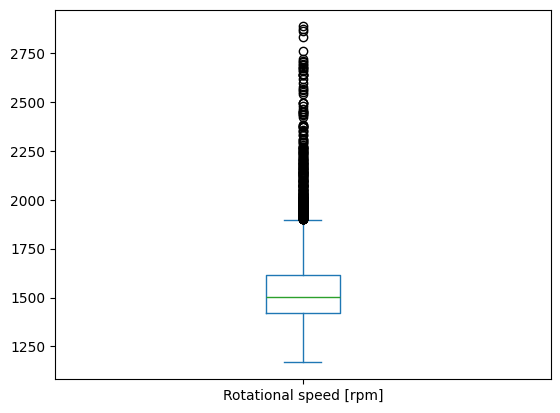

In [48]:
X_train["Rotational speed [rpm]"].plot(kind="box")
plt.show()

In [49]:
X_train['Rotational speed [rpm]'].sort_values(ascending=False).head(20)

1784    2886
463     2874
50      2861
847     2833
3369    2760
1095    2721
3867    2709
5334    2706
4302    2695
4048    2691
194     2678
4419    2676
3579    2672
4762    2663
4997    2659
5152    2643
3457    2639
9939    2636
6799    2636
8398    2617
Name: Rotational speed [rpm], dtype: int64

In [50]:
X_train["Rotational speed [rpm]"].describe()

count    8000.000000
mean     1539.356875
std       180.982943
min      1168.000000
25%      1422.000000
50%      1503.000000
75%      1613.000000
max      2886.000000
Name: Rotational speed [rpm], dtype: float64

**Rotational speed is highly right-skewed (skewness ≈ 2.01) and contains numerous statistical outliers according to the IQR method. However, the observed maximum of approximately 2886 rpm does not appear inherently invalid, so these observations will not be removed solely based on the IQR criterion. The skewness may reflect the natural distribution of operating speeds.**

In [51]:
# skewness handling
X_train["rpm log"] = np.log1p(X_train["Rotational speed [rpm]"])
X_train["rpm log"].skew()

np.float64(1.3239609709308227)

In [52]:
X_train["Torque [Nm]"].describe()

count    8000.000000
mean       40.003363
std        10.019546
min         3.800000
25%        33.200000
50%        40.100000
75%        46.800000
max        76.600000
Name: Torque [Nm], dtype: float64

In [53]:
X_train["Torque [Nm]"].sort_values(ascending=True).head(10)

1784     3.8
463      4.2
50       4.6
847      5.6
3369     8.0
1095     9.3
3867     9.7
5334     9.8
194     10.7
4419    10.8
Name: Torque [Nm], dtype: float64

# conclusion-IV
Rotational speed
→ Many statistical upper outliers
→ Values don't appear inherently invalid
→ Keep them
→ Apply log transformation to address skewness

Torque
→ Statistical outliers on both sides
→ Values appear physically plausible
→ Keep them
→ No outlier removal / no transformation

Air temperature
→ No concerning outliers → Keep

Process temperature
→ No concerning outliers → Keep

Tool wear
→ No concerning outliers → Keep

In [54]:
X_train.drop(columns=["rpm log"],inplace=True)

In [55]:
X_train.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
4058,M,302.0,310.9,1456,47.2,54,0,0,0,0,0
1221,M,297.0,308.3,1399,46.4,132,0,0,0,0,1
6895,M,301.0,311.6,1357,45.6,137,0,0,0,0,0
9863,L,298.9,309.8,1411,56.3,84,0,0,0,0,0
8711,L,297.1,308.5,1733,28.7,50,0,0,0,0,0




idea ->
Rotational speed → log1p,
Other numerical  → unchanged,
Type             → OneHotEncoder,
Binary columns   → unchanged


# Pipelines

**non scaled pipeline**

In [56]:
num_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Torque [Nm]',
    'Tool wear [min]'
]


cat_col = ["Type"]

# bin_cols=['TWF',
#           'HDF',
#           'PWF',
#           'OSF',
#           'RNF'] 


In [57]:
from sklearn.preprocessing import FunctionTransformer,OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessed_unscaled = ColumnTransformer(
    transformers=[
        ("rpm",FunctionTransformer(np.log1p),["Rotational speed [rpm]"]),
        ("num","passthrough",num_cols),
        ("cat",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_col),
        # ("bin","passthrough",bin_cols)
    ]
)

In [58]:
X_train_ns = preprocessed_unscaled.fit_transform(X_train)
X_test_ns = preprocessed_unscaled.transform(X_test)

In [59]:
print(X_train_ns.shape)
print(X_test_ns.shape)
# 5 bin col + 5 num_cols + 2 cat_col(after encode)
# 5 num_cols + 2 cat_cols

(8000, 7)
(2000, 7)


**scaled pipeline**

In [60]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
preprocessed_scaled = ColumnTransformer(
    transformers=[
        ("rpm",Pipeline([
            ("log",FunctionTransformer(np.log1p)),
            ("scale",StandardScaler())
        ]),
        ["Rotational speed [rpm]"]
        ),
        ("num",StandardScaler(),num_cols),
        ("cat",OneHotEncoder(drop='first',handle_unknown="ignore"),cat_col),
        # ("bin","passthrough",bin_cols)
    ]
)

In [61]:
X_train_scaled = preprocessed_scaled.fit_transform(X_train)
X_test_scaled = preprocessed_scaled.transform(X_test)

In [62]:
X_train_scaled.shape
X_test_scaled.shape

(2000, 7)

In [63]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    0.966125
1    0.033875
Name: proportion, dtype: float64


# MODEL BUILDING

In [64]:
# DUMMY MODEL
from sklearn.dummy import DummyClassifier
from sklearn.metrics import(
precision_score,
recall_score,
f1_score,
accuracy_score,
confusion_matrix,
classification_report,
average_precision_score
)

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)
y_prob_dummy = dummy.predict_proba(X_test)[:, 1]

In [65]:
print(accuracy_score(y_test,y_pred_dummy))
print(confusion_matrix(y_test,y_pred_dummy))
print(classification_report(y_test,y_pred_dummy))

0.966
[[1932    0]
 [  68    0]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



**Baseline Evaluation:
A DummyClassifier using the majority class strategy achieved 96.6% accuracy by predicting every observation as non-failure. However, it achieved 0% recall and 0% F1-score for the failure class, detecting none of the 68 actual failures in the test set. This demonstrates that accuracy is not an appropriate standalone metric for this highly imbalanced classification problem. Therefore, subsequent models will be evaluated primarily using failure-class precision, recall, F1-score, PR-AUC, and the confusion matrix.**

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("preprocessed",preprocessed_scaled),
    ("model",LogisticRegression(max_iter=1000,random_state=42))
])
lr_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessed',
                 ColumnTransformer(transformers=[('rpm',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Rotational speed [rpm]']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [67]:
lr_pred = lr_pipeline.predict(X_test)


In [68]:
print(classification_report(y_test,lr_pred))
print(confusion_matrix(y_test,lr_pred))
print(accuracy_score(y_test,lr_pred))
print(precision_score(y_test,lr_pred))
print(recall_score(y_test,lr_pred))
print(f1_score(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.80      0.12      0.21        68

    accuracy                           0.97      2000
   macro avg       0.88      0.56      0.59      2000
weighted avg       0.96      0.97      0.96      2000

[[1930    2]
 [  60    8]]
0.969
0.8
0.11764705882352941
0.20512820512820512


# new conclusion
**Conclusion — Feature Leakage Investigation
The initial Logistic Regression model achieved an unusually high 99.9% accuracy, with 97.1% recall for machine failures.
Although these results appear excellent, they raised a concern because the performance was suspiciously close to perfect.
The features TWF, HDF, PWF, OSF, and RNF are failure-mode indicators that are directly associated with specific types of machine failures.
Including these variables can provide the model with information that is too closely related to the target Machine failure, making the prediction task unrealistically easy.
Therefore, these features are removed from the predictive feature set to reduce the risk of target leakage/information leakage.
The model will instead predict machine failure using the machine's operating conditions such as temperature, rotational speed, torque, tool wear, and machine type.
The Logistic Regression model will then be retrained and evaluated to obtain a more realistic estimate of its predictive performance.**

# CROSS VALIDATION

In [69]:
from sklearn.model_selection import StratifiedKFold,cross_validate

cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [70]:
cv_results = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
)


In [71]:
print("Accuracy:", cv_results["test_accuracy"])
print("Precision:", cv_results["test_precision"])
print("Recall:", cv_results["test_recall"])
print("F1:", cv_results["test_f1"])

Accuracy: [0.97     0.97     0.97     0.969375 0.96875 ]
Precision: [0.875      0.75       0.66666667 0.85714286 0.77777778]
Recall: [0.12962963 0.16666667 0.22222222 0.11111111 0.12727273]
F1: [0.22580645 0.27272727 0.33333333 0.19672131 0.21875   ]


In [72]:
print("Mean Accuracy:", cv_results["test_accuracy"].mean())
print("Mean Precision:", cv_results["test_precision"].mean())
print("Mean Recall:", cv_results["test_recall"].mean())
print("Mean F1:", cv_results["test_f1"].mean())

Mean Accuracy: 0.969625
Mean Precision: 0.7853174603174603
Mean Recall: 0.15138047138047134
Mean F1: 0.2494676738297838


# model I conclusion
**Five-fold stratified cross-validation produced a mean accuracy of approximately 97.0%, with relatively stable accuracy across folds. However, the mean recall for the machine-failure class was only 15.1%, indicating that Logistic Regression consistently misses a large proportion of actual failures. Precision was comparatively higher at 78.5%, showing that predictions classified as failures are generally reliable, but the model is too conservative in identifying failures. The mean F1-score of 24.9% further indicates weak performance on the minority class. Therefore, Logistic Regression provides a stable baseline but is not sufficiently effective for machine-failure detection.**

In [73]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor",preprocessed_unscaled),
    ("model",RandomForestClassifier(n_estimators=200,random_state=42,class_weight='balanced'))
])

rf_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('rpm',
                                                  FunctionTransformer(func=<ufunc 'log1p'>),
                                                  ['Rotational speed [rpm]']),
                                                 ('num', 'passthrough',
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [74]:
rf_pred = rf_pipeline.predict(X_test)

In [75]:
print(classification_report(y_test,rf_pred))
print(confusion_matrix(y_test,rf_pred))
print(accuracy_score(y_test,rf_pred))
print(precision_score(y_test,rf_pred))
print(recall_score(y_test,rf_pred))
print(f1_score(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.92      0.49      0.63        68

    accuracy                           0.98      2000
   macro avg       0.95      0.74      0.81      2000
weighted avg       0.98      0.98      0.98      2000

[[1929    3]
 [  35   33]]
0.981
0.9166666666666666
0.4852941176470588
0.6346153846153846


# random forest conclusion
**Random Forest substantially outperformed Logistic Regression in detecting the minority failure class. Failure recall increased from approximately 11.8% to 48.5%, while precision increased from 80% to 91.7%. The model correctly identified 33 of the 68 actual failures while generating only 3 false positives. However, it still missed 35 actual failures, indicating that further improvement is required before the model is suitable for predictive maintenance. Cross-validation showed that Random Forest consistently outperformed Logistic Regression. Random Forest achieved a mean accuracy of 97.96%, precision of 92.99%, recall of 43.21%, and F1-score of 58.79%. The substantially higher recall indicates that Random Forest is considerably better at detecting the minority machine-failure class. Its high precision also indicates that most predicted failures are genuine. Although Random Forest still misses a considerable number of failures, its performance is substantially stronger and more consistent than Logistic Regression, making it the better candidate for further optimization.**

In [76]:
rf_cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring = [
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
)

In [77]:
print("Accuracy:", rf_cv_results["test_accuracy"])
print("Precision:", rf_cv_results["test_precision"])
print("Recall:", rf_cv_results["test_recall"])
print("F1:", rf_cv_results["test_f1"])

Accuracy: [0.981875 0.979375 0.979375 0.980625 0.976875]
Precision: [0.96296296 0.92       0.92       0.89655172 0.95      ]
Recall: [0.48148148 0.42592593 0.42592593 0.48148148 0.34545455]
F1: [0.64197531 0.58227848 0.58227848 0.62650602 0.50666667]


In [78]:
print("Mean Accuracy:", rf_cv_results["test_accuracy"].mean())
print("Mean Precision:", rf_cv_results["test_precision"].mean())
print("Mean Recall:", rf_cv_results["test_recall"].mean())
print("Mean F1:", rf_cv_results["test_f1"].mean())

Mean Accuracy: 0.9796250000000001
Mean Precision: 0.9299029374201788
Mean Recall: 0.43205387205387213
Mean F1: 0.5879409922860688


In [79]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor",preprocessed_unscaled),
    ("model",XGBClassifier(n_estimators=200,max_depth=4,learning_rate=0.1,random_state=42,eval_metric="logloss",scale_pos_weight=28.52))
])

xgb_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('rpm',
                                                  FunctionTransformer(func=<ufunc 'log1p'>),
                                                  ['Rotational speed [rpm]']),
                                                 ('num', 'passthrough',
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model',
                 XGBClassifier(base_score=None, boos...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [80]:
xgb_pred = xgb_pipeline.predict(X_test)

In [81]:
print(classification_report(y_test,xgb_pred))
print(confusion_matrix(y_test,xgb_pred))
print(accuracy_score(y_test,xgb_pred))
print(precision_score(y_test,xgb_pred))
print(recall_score(y_test,xgb_pred))
print(f1_score(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.55      0.81      0.65        68

    accuracy                           0.97      2000
   macro avg       0.77      0.89      0.82      2000
weighted avg       0.98      0.97      0.97      2000

[[1887   45]
 [  13   55]]
0.971
0.55
0.8088235294117647
0.6547619047619048


In [82]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
)

In [83]:
print("Accuracy",xgb_cv_results["test_accuracy"])
print("Precision:", xgb_cv_results["test_precision"])
print("Recall:", xgb_cv_results["test_recall"])
print("F1:", xgb_cv_results["test_f1"])

Accuracy [0.97375  0.970625 0.965    0.9775   0.9725  ]
Precision: [0.58108108 0.54666667 0.48780488 0.63235294 0.57333333]
Recall: [0.7962963  0.75925926 0.74074074 0.7962963  0.78181818]
F1: [0.671875   0.63565891 0.58823529 0.70491803 0.66153846]


In [84]:
print("Mean Accuracy:", xgb_cv_results["test_accuracy"].mean())
print("Mean Precision:", xgb_cv_results["test_precision"].mean())
print("Mean Recall:", xgb_cv_results["test_recall"].mean())
print("Mean F1:", xgb_cv_results["test_f1"].mean())

Mean Accuracy: 0.971875
Mean Precision: 0.5642477800612664
Mean Recall: 0.7748821548821548
Mean F1: 0.6524451406343352


# xgb conclusion
**XGBoost with scale_pos_weight=28.52 is currently the best model. It achieved 80.9% recall and 65.5% F1 on the held-out test set, detecting 55 of 68 failures. However, its 55% precision resulted in 45 false positives, so further optimization is needed to improve the precision–recall trade-off.**

> ***XGBOOST IS OUR FINAL MODEL***

# HYPERPARAMETER TUNING

In [85]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5, 7]
}

In [86]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [87]:
xgb_search.fit(X_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('rpm',
                                                                               FunctionTransformer(func=<ufunc 'log1p'>),
                                                                               ['Rotational '
                                                                                'speed '
                                                                                '[rpm]']),
                                                                              ('num',
                                                                               'passthrough',
                                                                               ['Air '
                                                                                'temperature '
                                                                                '[K]',
                                                                                'Process '
                                                                                'temperature '
                                                                                '[K]',
                                                                                'Torque '
                                                                                '[Nm]',
                                                                                'Tool '
                                                                                'wear '
                                                                                '[min]']),
                                                                              ('cat',
                                                                               O...
                                                            n_jobs=None,
                                                            num_parallel_tree=None, ...))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    0.9, 1.0],
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.1,
                                                                 0.2],
                                        'model__max_depth': [2, 3, 4, 5, 6],
                                        'model__min_child_weight': [1, 3, 5, 7],
                                        'model__n_estimators': [100, 200, 300,
                                                                500],
                                        'model__subsample': [0.7, 0.8, 0.9,
                                                             1.0]},
                   random_state=42, scoring='f1', verbose=1)

In [88]:
print("Best F1:", xgb_search.best_score_)
print("Best Parameters:")
print(xgb_search.best_params_)

Best F1: 0.733716674464338
Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}


In [89]:
best_xgb = xgb_search.best_estimator_
tuned_pred = best_xgb.predict(X_test)

In [90]:
print(classification_report(y_test, tuned_pred))
print(confusion_matrix(y_test, tuned_pred))

print("Accuracy:", accuracy_score(y_test, tuned_pred))
print("Precision:", precision_score(y_test, tuned_pred))
print("Recall:", recall_score(y_test, tuned_pred))
print("F1:", f1_score(y_test, tuned_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.76      0.78      0.77        68

    accuracy                           0.98      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.98      0.98      0.98      2000

[[1915   17]
 [  15   53]]
Accuracy: 0.984
Precision: 0.7571428571428571
Recall: 0.7794117647058824
F1: 0.7681159420289855


# THRESHOLD TESTING

In [91]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [92]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

for threshold in thresholds:
    oof_pred = (oof_proba >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_train, oof_pred):.3f} | "
        f"Recall: {recall_score(y_train, oof_pred):.3f} | "
        f"F1: {f1_score(y_train, oof_pred):.3f}"
    )

Threshold: 0.30 | Precision: 0.675 | Recall: 0.775 | F1: 0.722
Threshold: 0.35 | Precision: 0.685 | Recall: 0.764 | F1: 0.723
Threshold: 0.40 | Precision: 0.708 | Recall: 0.753 | F1: 0.730
Threshold: 0.45 | Precision: 0.729 | Recall: 0.734 | F1: 0.732
Threshold: 0.50 | Precision: 0.738 | Recall: 0.727 | F1: 0.732
Threshold: 0.55 | Precision: 0.748 | Recall: 0.723 | F1: 0.735
Threshold: 0.60 | Precision: 0.762 | Recall: 0.708 | F1: 0.734
Threshold: 0.65 | Precision: 0.781 | Recall: 0.697 | F1: 0.737
Threshold: 0.70 | Precision: 0.803 | Recall: 0.690 | F1: 0.742


In [93]:
best_threshold = 0.70

test_proba = best_xgb.predict_proba(X_test)[:, 1]

test_pred_threshold = (
    test_proba >= best_threshold
).astype(int)

In [94]:
print(classification_report(y_test, test_pred_threshold))
print(confusion_matrix(y_test, test_pred_threshold))

print("Accuracy:", accuracy_score(y_test, test_pred_threshold))
print("Precision:", precision_score(y_test, test_pred_threshold))
print("Recall:", recall_score(y_test, test_pred_threshold))
print("F1:", f1_score(y_test, test_pred_threshold))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.83      0.76      0.79        68

    accuracy                           0.99      2000
   macro avg       0.91      0.88      0.89      2000
weighted avg       0.99      0.99      0.99      2000

[[1921   11]
 [  16   52]]
Accuracy: 0.9865
Precision: 0.8253968253968254
Recall: 0.7647058823529411
F1: 0.7938931297709924


# ERROR ANALYSIS

In [96]:
test_results = X_test.copy()

test_results["actual"] = y_test.values
test_results["predicted"] = test_pred_threshold
test_results["probability"] = test_proba

In [97]:
false_negatives = test_results[
    (test_results["actual"] == 1) &
    (test_results["predicted"] == 0)
]

false_positives = test_results[
    (test_results["actual"] == 0) &
    (test_results["predicted"] == 1)
]

In [98]:
print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

False Negatives: 16
False Positives: 11


In [100]:
false_negatives

# print(true_positives.to_string())
# true_positives = test_results[
#     (test_results["actual"] == 1) &
#     (test_results["predicted"] == 1)
# ]

# print(true_positives.to_string())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,actual,predicted,probability
4851,L,303.7,312.1,1363,51.8,90,0,1,0,0,0,1,0,0.154841
4632,M,302.9,311.2,1330,53.7,200,0,1,0,0,0,1,0,0.576934
7884,L,300.8,312.4,1465,59.1,91,0,0,1,0,0,1,0,0.002802
9174,L,297.8,308.9,1871,25.6,200,1,0,0,0,0,1,0,0.000053
2671,M,299.7,309.3,1399,41.9,221,1,0,0,0,0,1,0,0.001120
2864,H,300.6,309.4,1380,47.6,246,1,0,0,0,0,1,0,0.249977
4307,L,301.4,309.9,1259,63.9,20,0,1,0,0,0,1,0,0.161190
3695,L,302.2,311.3,1530,37.3,207,1,0,0,0,0,1,0,0.007144
7087,L,300.6,310.3,1648,30.5,217,1,0,0,0,0,1,0,0.015609
2941,M,300.7,309.6,1996,19.8,203,1,0,0,0,0,1,0,0.008448


In [101]:
false_negatives.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],actual,predicted,probability
count,16.000000,16.000000,16.00000,16.000000,16.000000,16.0,16.0,16.000000
mean,300.643750,310.300000,1509.87500,42.368750,177.187500,1.0,0.0,0.081840
std,1.984261,1.421736,206.25805,13.172381,64.231061,0.0,0.0,0.151644
min,297.200000,308.000000,1259.00000,19.800000,20.000000,1.0,0.0,0.000037
25%,299.375000,309.375000,1373.25000,30.125000,150.250000,1.0,0.0,0.002385
50%,300.650000,310.100000,1423.50000,44.750000,201.500000,1.0,0.0,0.011980
75%,302.050000,311.400000,1623.25000,52.275000,218.000000,1.0,0.0,0.083262
max,303.700000,312.400000,1996.00000,63.900000,246.000000,1.0,0.0,0.576934


In [102]:
true_positives = test_results[
    (test_results["actual"] == 1) &
    (test_results["predicted"] == 1)
]

print(true_positives.to_string())

     Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min] TWF HDF PWF OSF RNF  actual  predicted  probability
1391    L                298.9                    310.2                    2737          8.8              142   0   0   1   0   0       1          1     0.992473
4495    L                302.6                    310.4                    1359         57.2               67   0   1   0   0   0       1          1     0.999607
8582    M                297.5                    308.1                    1334         72.0              151   0   0   1   0   0       1          1     0.996629
9664    L                299.1                    310.2                    1317         54.8              231   0   0   0   1   0       1          1     0.999613
3806    M                302.3                    310.9                    1360         44.0               67   0   1   0   0   0       1          1     0.947538
2444    L                299

In [104]:
true_positives.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],actual,predicted,probability
count,52.000000,52.000000,52.000000,52.000000,52.000000,52.0,52.0,52.000000
mean,300.773077,310.086538,1470.250000,52.551923,145.980769,1.0,1.0,0.964728
std,2.219355,1.354590,405.626645,15.713046,61.831679,0.0,0.0,0.060466
min,295.600000,306.100000,1227.000000,5.800000,17.000000,1.0,1.0,0.743340
25%,298.600000,309.175000,1325.750000,50.700000,107.750000,1.0,1.0,0.969114
50%,301.850000,310.400000,1349.500000,55.850000,149.500000,1.0,1.0,0.992658
75%,302.525000,310.900000,1373.750000,61.000000,203.000000,1.0,1.0,0.997587
max,303.400000,312.400000,2825.000000,72.000000,246.000000,1.0,1.0,0.999943


In [105]:
compare_fn = pd.DataFrame({
    "True Positives": true_positives[
        ['Air temperature [K]',
         'Process temperature [K]',
         'Rotational speed [rpm]',
         'Torque [Nm]',
         'Tool wear [min]']
    ].mean(),

    "False Negatives": false_negatives[
        ['Air temperature [K]',
         'Process temperature [K]',
         'Rotational speed [rpm]',
         'Torque [Nm]',
         'Tool wear [min]']
    ].mean()
})

print(compare_fn)

                         True Positives  False Negatives
Air temperature [K]          300.773077        300.64375
Process temperature [K]      310.086538        310.30000
Rotational speed [rpm]      1470.250000       1509.87500
Torque [Nm]                   52.551923         42.36875
Tool wear [min]              145.980769        177.18750


In [106]:
compare_fn["Difference %"] = (
    (compare_fn["False Negatives"] -
     compare_fn["True Positives"])
    / compare_fn["True Positives"]
) * 100

print(compare_fn)

                         True Positives  False Negatives  Difference %
Air temperature [K]          300.773077        300.64375     -0.042998
Process temperature [K]      310.086538        310.30000      0.068839
Rotational speed [rpm]      1470.250000       1509.87500      2.695120
Torque [Nm]                   52.551923         42.36875    -19.377356
Tool wear [min]              145.980769        177.18750     21.377289


In [107]:
true_negatives = test_results[
    (test_results["actual"] == 0) &
    (test_results["predicted"] == 0)
]

compare_fp = pd.DataFrame({
    "True Negatives": true_negatives[
        ['Air temperature [K]',
         'Process temperature [K]',
         'Rotational speed [rpm]',
         'Torque [Nm]',
         'Tool wear [min]']
    ].mean(),

    "False Positives": false_positives[
        ['Air temperature [K]',
         'Process temperature [K]',
         'Rotational speed [rpm]',
         'Torque [Nm]',
         'Tool wear [min]']
    ].mean()
})

print(compare_fp)

                         True Negatives  False Positives
Air temperature [K]          299.970536       301.072727
Process temperature [K]      309.994118       310.827273
Rotational speed [rpm]      1538.813118      1475.909091
Torque [Nm]                   39.528371        45.236364
Tool wear [min]              107.300364       134.545455


In [108]:
print("TP:")
print(true_positives["Type"].value_counts())

print("\nFN:")
print(false_negatives["Type"].value_counts())

print("\nTN:")
print(true_negatives["Type"].value_counts())

print("\nFP:")
print(false_positives["Type"].value_counts())

TP:
Type
L    29
M    20
H     3
Name: count, dtype: int64

FN:
Type
L    9
M    5
H    2
Name: count, dtype: int64

TN:
Type
L    1123
M     589
H     209
Name: count, dtype: int64

FP:
Type
L    9
M    2
Name: count, dtype: int64


# ERROR ANALYSIS CONCLUSION
**Error Analysis:
The model produced 16 false negatives and 11 false positives on the test set. Comparing false negatives with correctly detected failures showed that missed failures had substantially lower average torque and higher average tool wear, while temperature values were relatively similar. False positives, compared with correctly classified healthy machines, showed higher average temperature, torque, and tool wear and somewhat lower rotational speed. These patterns suggest that some healthy machines exhibit feature combinations similar to failure cases, while some actual failures have feature patterns that are less strongly associated with failure in the learned model. These observations indicate areas where the model may have difficulty distinguishing borderline or atypical cases.**

# EXPLAINABILITY

In [109]:
xgb_model = best_xgb.named_steps["model"]

In [111]:
X_train_transformed = best_xgb.named_steps["preprocessor"].transform(X_train)
feature_names = (
    best_xgb
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(feature_names)

AttributeError: Transformer rpm (type FunctionTransformer) does not provide get_feature_names_out.

In [112]:
feature_names = [
    "Rotational speed [rpm]",
    "Air temperature [K]",
    "Process temperature [K]",
    "Torque [Nm]",
    "Tool wear [min]"
]
encoder = best_xgb.named_steps["preprocessor"].named_transformers_["cat"]

print(encoder.get_feature_names_out())

['Type_L' 'Type_M']


In [113]:
feature_names = [
    "Rotational speed [rpm]",
    "Air temperature [K]",
    "Process temperature [K]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Type_L",
    "Type_M"
]

In [114]:
X_train_transformed = best_xgb.named_steps["preprocessor"].transform(X_train)

In [115]:
print(X_train_transformed.shape)
print(len(feature_names))

(8000, 7)
7


In [118]:
import shap
xgb_model = best_xgb.named_steps["model"]

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_train_transformed)

In [119]:
print(shap_values.shape)

(8000, 7)


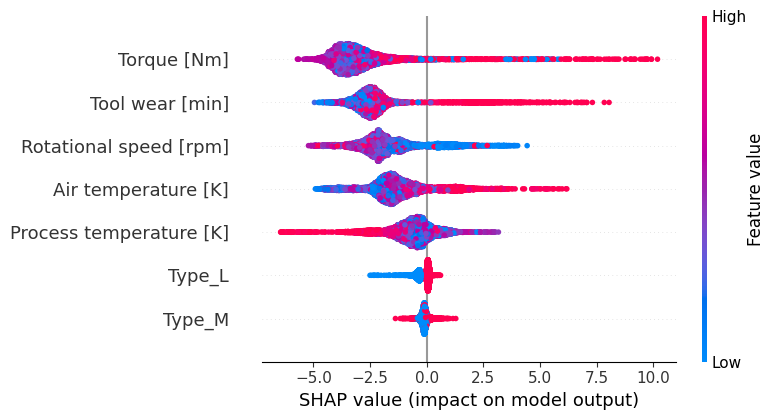

In [120]:
shap.summary_plot(
    shap_values,
    X_train_transformed,
    feature_names=feature_names
)

In [121]:
sample_index = true_positives.index[0]
print(sample_index)

1391


In [124]:
sample = X_test.loc[[sample_index]]
sample_transformed = best_xgb.named_steps["preprocessor"].transform(sample)
sample_shap = explainer.shap_values(sample_transformed)

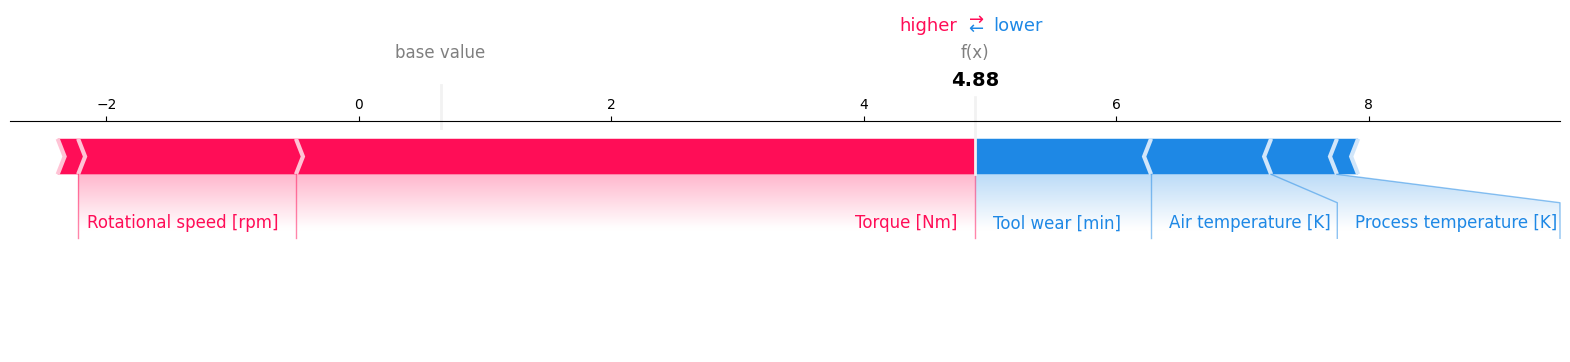

In [125]:
shap.force_plot(
    explainer.expected_value,
    sample_shap[0],
    feature_names=feature_names,
    matplotlib=True
)

In [126]:
fn_index = false_negatives.index[0]

fn_sample = X_test.loc[[fn_index]]

print("Index:", fn_index)
print(fn_sample)

Index: 4851
     Type  Air temperature [K]  Process temperature [K]  \
4851    L                303.7                    312.1   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min] TWF HDF PWF OSF RNF  
4851                    1363         51.8               90   0   1   0   0   0  


In [127]:
fn_transformed = best_xgb.named_steps["preprocessor"].transform(fn_sample)

In [128]:
fn_shap = explainer.shap_values(fn_transformed)

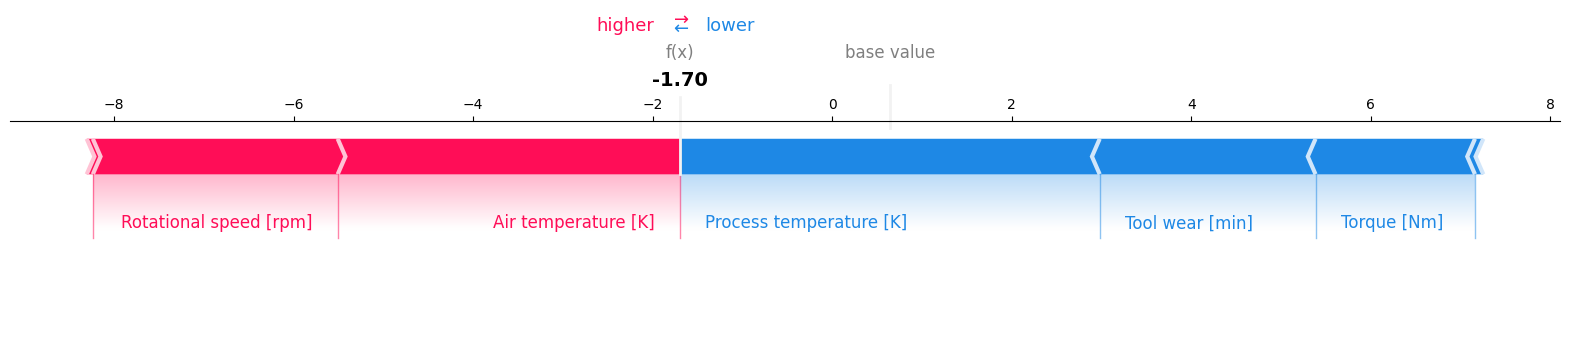

In [129]:
shap.force_plot(
    explainer.expected_value,
    fn_shap[0],
    feature_names=feature_names,
    matplotlib=True
)

# CONCLUSION OF EXPLAINABILITY
**Error analysis was performed to understand the types of mistakes made by the final XGBoost model. The model produced 16 false negatives and 11 false positives on the test set. Comparison of correctly and incorrectly classified samples showed that missed failures generally had lower average torque and higher tool wear than correctly detected failures. False-positive cases also showed feature patterns that were more similar to failure cases, suggesting that some healthy machines are difficult for the model to distinguish from failing machines.

SHAP was then used to explain the model's predictions. Global SHAP analysis showed that torque, tool wear, and rotational speed were the most influential features, while machine type had relatively low influence. Local SHAP explanations demonstrated how individual feature values contributed toward or away from a failure prediction. In a false-negative example, rotational speed and air temperature pushed the prediction toward failure, while process temperature, tool wear, and torque pushed it toward non-failure, ultimately causing the model to miss the actual failure.

Overall, error analysis helped identify where the model struggles, while SHAP provided insight into why individual predictions were made. Together, these techniques improved the interpretability and understanding of the final machine-failure prediction model.

🧠 What you learned today**
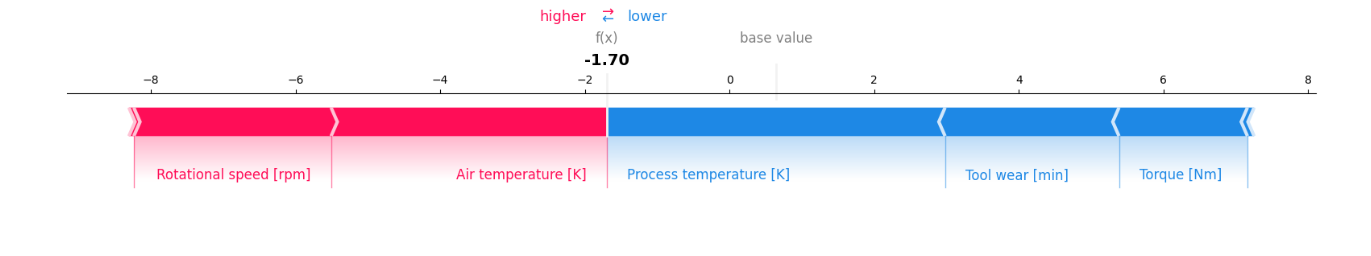